In [1]:
import wot
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
from pathlib import Path
from collections import defaultdict
from scipy import sparse

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import chronopack as cp
from chronopack.tl._trajectories import (
    PlotHardClusterMassProportionsOverTime,
    fate_umap_2x2_scanpy,
    mass_retention_plots_and_umap,
)


# Function definitions

## Waddington‑OT (Transport maps)
Following the official [WOT notebooks](https://github.com/broadinstitute/wot/tree/master/notebooks), we compute transport maps between successive time points.
Make sure `adata.obs['time']` (integer or float) exists and reflects the sampling time in *hours/days* used in the Seurat notebook.

In [93]:
adata_hvg = sc.read_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')
adata_hvg.obs['time'] = pd.to_numeric(adata_hvg.obs['time'].astype(str))
adata_hvg.X = adata_hvg.layers['corrected'].copy()

TMAP_DIR = '../intmd/tmaps.SingleCell.1e4/'

wot_out = cp.tl.get_trajectories(
    adata_hvg,
    tmap_dir=TMAP_DIR,
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    graph_key='ot_graph',
    umap_key='X_ot_umap',
    umap_random_state=10,
)

tmaps = wot_out['tmaps']
transitions_long = wot_out['transitions_long']
tmats = wot_out['tmats']
T_full = wot_out['T_full']
T_pruned = wot_out['T_pruned']
T_sym = wot_out['T_sym']
key = 'X_ot_umap'
key_out = key


Built 11 transport matrices.


# Construct forward transition kernel (+ pruned & symmetric variants)

# Cluster trajectories

In [ ]:
W_pruned = cp.tl.cluster_cell_state_trajectories(
    adata_hvg,
    T_pruned,
    cluster_key="traj_clusters",
    resolution=0.3,
    terminal_topk=200,
    graph_topk=500,
    random_state=0,
)
sc.pl.embedding(
    adata_hvg,
    basis="umap",
    color=["time", "traj_clusters", "total_counts", "n_genes_by_counts", "NFKBIA", "HBE1"],
    ncols=3,
    cmap="viridis",
)


# Calculate terminal fates & trajectory cluster mass retention

Stored adata.obsm['terminal_fate_probs_traj'] with shape (6857, 2)
Fates (2): ['0', '1']


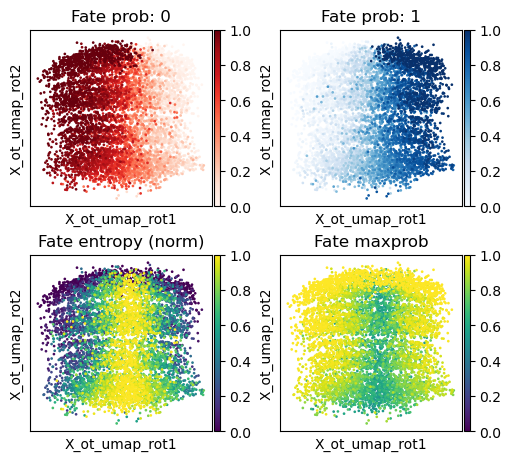

(<Figure size 500x450 with 8 Axes>,
 array([[<Axes: title={'center': 'Fate prob: 0'}, xlabel='X_ot_umap_rot1', ylabel='X_ot_umap_rot2'>,
         <Axes: title={'center': 'Fate prob: 1'}, xlabel='X_ot_umap_rot1', ylabel='X_ot_umap_rot2'>],
        [<Axes: title={'center': 'Fate entropy (norm)'}, xlabel='X_ot_umap_rot1', ylabel='X_ot_umap_rot2'>,
         <Axes: title={'center': 'Fate maxprob'}, xlabel='X_ot_umap_rot1', ylabel='X_ot_umap_rot2'>]],
       dtype=object))

In [46]:
F, fate_names = cp.tl.compute_terminal_fate_probabilities(adata_hvg, terminal_cluster_key="traj_clusters", out_key="terminal_fate_probs_traj")
fate_umap_2x2_scanpy(adata_hvg, size=15, umap_basis=key_out)

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


Overall mass retention (mean over steps): 0.8563
Overall analytic baseline (mean over steps): 0.5057
Overall permutation baseline (mean over steps): 0.5052


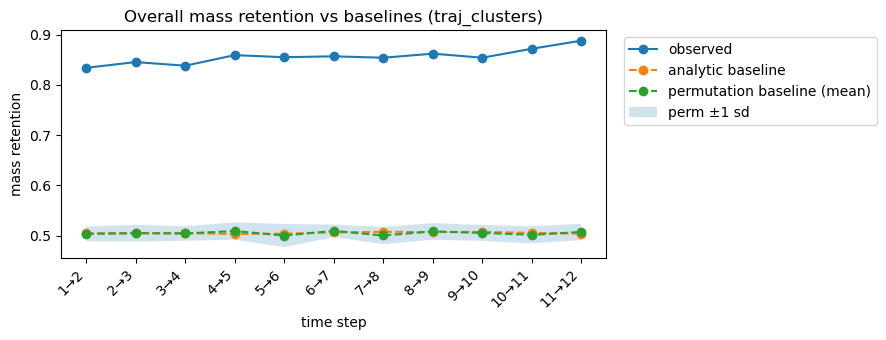

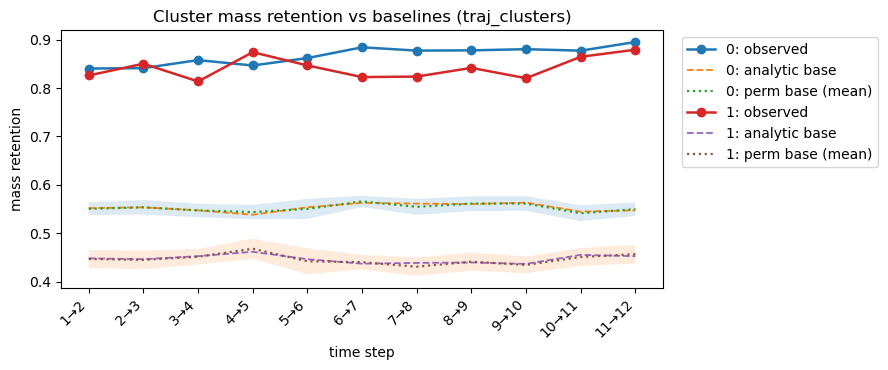

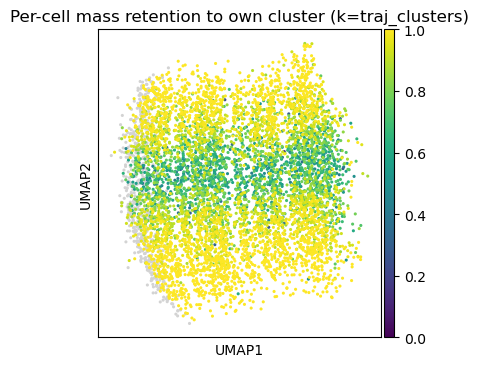

In [97]:
out = mass_retention_plots_and_umap(adata_hvg, T_pruned, 
                                    cluster_key="traj_clusters", 
                                    n_reps=50, clusters_to_plot=["0","1"], 
                                    umap_basis="umap", size=20)

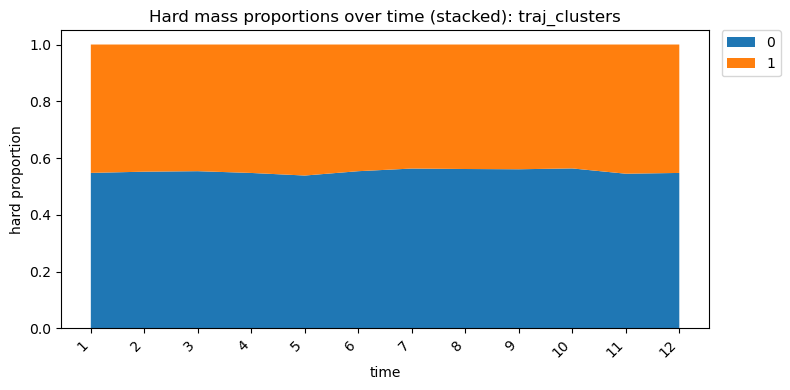

In [98]:
PlotHardClusterMassProportionsOverTime(adata_hvg)

# Visualize on original UMAP

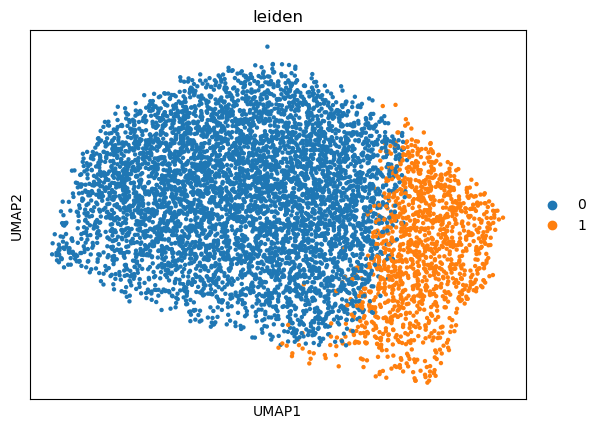

In [99]:
tmp = sc.read_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')
adata_hvg.obsm['X_umap_original'] = tmp.obsm['X_umap'].copy()

sc.tl.leiden(tmp, resolution=0.3)
adata_hvg.obs['leiden'] = tmp.obs['leiden'].copy()

In [105]:
adata = sc.read_h5ad('../output/adata_full.1e4-variant.chk0.h5ad')

adata.obs = adata_hvg.obs.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.uns = adata_hvg.uns.copy()

adata.write_h5ad('../output/adata_full.1e4-variant.chk1.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.1e4-variant.chk1.h5ad')